# FT1 — Image Compression and Huffman Coding
Run the cells from top to bottom. Upload one JPG/PNG image. The notebook converts it to a 256×256 PPM so the C program can read it, then the C program performs grayscale conversion, 8×8 block DCT, quantization, zigzag scanning, RLE, Huffman coding, decoding, inverse quantization, IDCT and reconstruction.


In [1]:
from google.colab import files
uploaded = files.upload()
input_name = next(iter(uploaded))
print('Uploaded:', input_name)


Saving myimage.jpeg to myimage.jpeg
Uploaded: myimage.jpeg


In [7]:
from PIL import Image

img = Image.open(input_name)
img = img.convert("RGB")
img = img.resize((256, 256))
img.save("input.ppm")

print("Converted to 256 x 256 input.ppm")

Converted to 256 x 256 input.ppm


In [8]:
%%writefile image_compression.c

#include <stdio.h>
#include <stdlib.h>
#include <string.h>
#include <math.h>

#define MAXSYMBOLS 20070
#define MAXCODE 128

typedef struct { int type; int value; } Token;
typedef struct { int sym; long long freq; int left, right, parent; } Node;

static const int Q[8][8] = {
{16,11,10,16,24,40,51,61},
{12,12,14,19,26,58,60,55},
{14,13,16,24,40,57,69,56},
{14,17,22,29,51,87,80,62},
{18,22,37,56,68,109,103,77},
{24,35,55,64,81,104,113,92},
{49,64,78,87,103,121,120,101},
{72,92,95,98,112,100,103,99}
};

static const int zz[64][2] = {
{0,0},{0,1},{1,0},{2,0},{1,1},{0,2},{0,3},{1,2},
{2,1},{3,0},{4,0},{3,1},{2,2},{1,3},{0,4},{0,5},
{1,4},{2,3},{3,2},{4,1},{5,0},{6,0},{5,1},{4,2},
{3,3},{2,4},{1,5},{0,6},{0,7},{1,6},{2,5},{3,4},
{4,3},{5,2},{6,1},{7,0},{7,1},{6,2},{5,3},{4,4},
{3,5},{2,6},{1,7},{2,7},{3,6},{4,5},{5,4},{6,3},
{7,2},{7,3},{6,4},{5,5},{4,6},{3,7},{4,7},{5,6},
{6,5},{7,4},{7,5},{6,6},{5,7},{6,7},{7,6},{7,7}
};

static int symbol_id(Token t) {
    if (t.type == 0) return t.value + 10000;
    if (t.type == 1) return 20001 + t.value;
    return 20065;
}

static Token id_token(int id) {
    Token t;
    if (id >= 0 && id <= 20000) { t.type=0; t.value=id-10000; }
    else if (id >= 20002 && id <= 20064) { t.type=1; t.value=id-20001; }
    else { t.type=2; t.value=0; }
    return t;
}

static int read_ppm(const char *name, int *w, int *h, unsigned char **rgb) {
    FILE *f=fopen(name,"rb");
    if(!f) return 0;
    char magic[3];
    if(fscanf(f,"%2s",magic)!=1 || strcmp(magic,"P6")!=0){ fclose(f); return 0; }
    int c;
    do { c=fgetc(f); } while(c==' '||c=='\n'||c=='\r'||c=='\t');
    ungetc(c,f);
    int maxv;
    if(fscanf(f,"%d %d %d",w,h,&maxv)!=3 || maxv!=255){ fclose(f); return 0; }
    fgetc(f);
    *rgb=(unsigned char*)malloc((size_t)(*w)*(*h)*3);
    if(!*rgb){ fclose(f); return 0; }
    size_t n=fread(*rgb,1,(size_t)(*w)*(*h)*3,f);
    fclose(f);
    return n==(size_t)(*w)*(*h)*3;
}

static int write_pgm(const char *name, int w, int h, const unsigned char *img) {
    FILE *f=fopen(name,"wb");
    if(!f) return 0;
    fprintf(f,"P5\n%d %d\n255\n",w,h);
    fwrite(img,1,(size_t)w*h,f);
    fclose(f);
    return 1;
}

static void grayscale(const unsigned char *rgb, unsigned char *gray, int w, int h) {
    for(int i=0;i<w*h;i++) {
        int r=rgb[3*i], g=rgb[3*i+1], b=rgb[3*i+2];
        int y=(299*r+587*g+114*b+500)/1000;
        if(y<0)y=0; if(y>255)y=255;
        gray[i]=(unsigned char)y;
    }
}

static void dct8(const double in[8][8], double out[8][8]) {
    for(int u=0;u<8;u++) for(int v=0;v<8;v++) {
        double cu=(u==0)?1.0/sqrt(2.0):1.0;
        double cv=(v==0)?1.0/sqrt(2.0):1.0;
        double s=0.0;
        for(int x=0;x<8;x++) for(int y=0;y<8;y++)
            s += in[x][y]*cos((2*x+1)*u*M_PI/16.0)*cos((2*y+1)*v*M_PI/16.0);
        out[u][v]=0.25*cu*cv*s;
    }
}

static void idct8(const double in[8][8], double out[8][8]) {
    for(int x=0;x<8;x++) for(int y=0;y<8;y++) {
        double s=0.0;
        for(int u=0;u<8;u++) for(int v=0;v<8;v++) {
            double cu=(u==0)?1.0/sqrt(2.0):1.0;
            double cv=(v==0)?1.0/sqrt(2.0):1.0;
            s += cu*cv*in[u][v]*cos((2*x+1)*u*M_PI/16.0)*cos((2*y+1)*v*M_PI/16.0);
        }
        out[x][y]=0.25*s;
    }
}

static void quantize_block(const double dct[8][8], int q[8][8]) {
    for(int i=0;i<8;i++) for(int j=0;j<8;j++) q[i][j]=(int)llround(dct[i][j]/Q[i][j]);
}

static void inverse_quantize(const int q[8][8], double d[8][8]) {
    for(int i=0;i<8;i++) for(int j=0;j<8;j++) d[i][j]=(double)q[i][j]*Q[i][j];
}

static void zigzag(const int q[8][8], int z[64]) {
    for(int k=0;k<64;k++) z[k]=q[zz[k][0]][zz[k][1]];
}

static void izigzag(const int z[64], int q[8][8]) {
    for(int k=0;k<64;k++) q[zz[k][0]][zz[k][1]]=z[k];
}

static int rle_encode(const int z[64], Token *out) {
    int n=0, run=0;
    for(int i=0;i<64;i++) {
        if(z[i]==0) run++;
        else {
            if(run>0) { out[n].type=1; out[n].value=run; n++; run=0; }
            out[n].type=0; out[n].value=z[i]; n++;
        }
    }
    out[n].type=2; out[n].value=0; n++;
    return n;
}

static void token_text(FILE *f, Token t) {
    if(t.type==0) fprintf(f,"%d",t.value);
    else if(t.type==1) fprintf(f,"(0,%d)",t.value);
    else fprintf(f,"EOB");
}

static void print_matrix_int(FILE *f, const int a[8][8]) {
    for(int i=0;i<8;i++){ for(int j=0;j<8;j++) fprintf(f,"%8d",a[i][j]); fprintf(f,"\n"); }
}

static void print_matrix_double(FILE *f, const double a[8][8]) {
    for(int i=0;i<8;i++){ for(int j=0;j<8;j++) fprintf(f,"%10.2f",a[i][j]); fprintf(f,"\n"); }
}

static int build_huffman(long long freq[MAXSYMBOLS], Node *nodes, int *root, int *used_syms) {
    int n=0;
    for(int s=0;s<MAXSYMBOLS;s++) if(freq[s]>0) {
        nodes[n].sym=s; nodes[n].freq=freq[s]; nodes[n].left=-1; nodes[n].right=-1; nodes[n].parent=-1; n++;
        used_syms[n-1]=s;
    }
    if(n==1){ *root=0; return n; }
    int total=n;
    while(1) {
        int a=-1,b=-1;
        for(int i=0;i<total;i++) if(nodes[i].parent==-1) {
            if(a==-1 || nodes[i].freq<nodes[a].freq) { b=a; a=i; }
            else if(b==-1 || nodes[i].freq<nodes[b].freq) b=i;
        }
        if(b==-1) break;
        nodes[total].sym=-1;
        nodes[total].freq=nodes[a].freq+nodes[b].freq;
        nodes[total].left=a; nodes[total].right=b; nodes[total].parent=-1;
        nodes[a].parent=total; nodes[b].parent=total;
        total++;
    }
    *root=total-1;
    return total;
}

static void make_codes(Node *nodes, int root, char codes[MAXSYMBOLS][MAXCODE]) {
    for(int s=0;s<MAXSYMBOLS;s++) codes[s][0]='\0';
    if(nodes[root].left==-1) {
        sprintf(codes[nodes[root].sym],"0");
        return;
    }
    char path[MAXCODE];
    void walk(int idx, int depth) {
        if(nodes[idx].left==-1) {
            path[depth]='\0';
            strcpy(codes[nodes[idx].sym],path);
            return;
        }
        path[depth]='0'; walk(nodes[idx].left,depth+1);
        path[depth]='1'; walk(nodes[idx].right,depth+1);
    }
    walk(root,0);
}

static long long encode_tokens(Token *tokens, int nt, char codes[MAXSYMBOLS][MAXCODE], FILE *bitf, int show_limit) {
    long long bits=0;
    for(int i=0;i<nt;i++) {
        int id=symbol_id(tokens[i]);
        const char *c=codes[id];
        int len=(int)strlen(c);
        bits+=len;
        fputs(c,bitf);
    }
    fputc('\n',bitf);
    return bits;
}

int main(void) {
    const char *infile="input.ppm";
    int ow,oh;
    unsigned char *rgb=NULL;
    if(!read_ppm(infile,&ow,&oh,&rgb)) {
        printf("Could not read input.ppm\n");
        return 1;
    }

    int w=((ow+7)/8)*8, h=((oh+7)/8)*8;
    unsigned char *gray=(unsigned char*)malloc((size_t)w*h);
    unsigned char *recon=(unsigned char*)malloc((size_t)w*h);
    if(!gray||!recon){ free(rgb); return 1; }

    unsigned char *tmpgray=(unsigned char*)malloc((size_t)ow*oh);
    grayscale(rgb,tmpgray,ow,oh);
    for(int y=0;y<h;y++) for(int x=0;x<w;x++)
        gray[y*w+x]=(x<ow&&y<oh)?tmpgray[y*ow+x]:128;
    free(tmpgray);

    write_pgm("grayscale.pgm",w,h,gray);

    long long freq[MAXSYMBOLS]={0};
    Token *all=(Token*)malloc((size_t)w*h/64*70*sizeof(Token));
    size_t allcap=(size_t)w*h/64*70, alln=0;
    Token sample[70]; int sample_n=0;
    int sample_bx=(w/2/8)*8, sample_by=(h/2/8)*8;
    int sample_q[8][8], sample_z[64];
    double sample_shift[8][8], sample_dct[8][8];

    for(int by=0;by<h;by+=8) for(int bx=0;bx<w;bx+=8) {
        double in[8][8], d[8][8];
        int q[8][8], z[64];
        for(int i=0;i<8;i++) for(int j=0;j<8;j++) {
            in[i][j]=(double)gray[(by+i)*w+(bx+j)]-128.0;
        }
        dct8(in,d);
        quantize_block(d,q);
        zigzag(q,z);
        Token t[70]; int tn=rle_encode(z,t);
        if(by==sample_by&&bx==sample_bx) {
            memcpy(sample_shift,in,sizeof(in));
            memcpy(sample_dct,d,sizeof(d));
            memcpy(sample_q,q,sizeof(q));
            memcpy(sample_z,z,sizeof(z));
            memcpy(sample,t,sizeof(t));
            sample_n=tn;
        }
        for(int k=0;k<tn;k++) {
            if(alln>=allcap){ allcap*=2; all=(Token*)realloc(all,allcap*sizeof(Token)); }
            all[alln++]=t[k];
            freq[symbol_id(t[k])]++;
        }
    }

    Node *nodes=(Node*)malloc((MAXSYMBOLS*2)*sizeof(Node));
    int *used=(int*)malloc(MAXSYMBOLS*sizeof(int));
    int root=0;
    int node_count=build_huffman(freq,nodes,&root,used);
    char (*codes)[MAXCODE]=(char (*)[MAXCODE])calloc(MAXSYMBOLS,sizeof(*codes));
    make_codes(nodes,root,codes);

    FILE *f=fopen("outputs.txt","w");
    fprintf(f,"IMAGE COMPRESSION OUTPUTS\n\n");
    fprintf(f,"Original image dimensions: %d x %d\n",ow,oh);
    fprintf(f,"Padded dimensions: %d x %d\n\n",w,h);
    fprintf(f,"8x8 SAMPLE BLOCK (center block)\n");
    int raw[8][8];
    for(int i=0;i<8;i++) for(int j=0;j<8;j++) raw[i][j]=gray[(sample_by+i)*w+(sample_bx+j)];
    print_matrix_int(f,raw);
    fprintf(f,"\nLEVEL SHIFTED BLOCK\n");
    print_matrix_double(f,sample_shift);
    fprintf(f,"\nDCT COEFFICIENTS\n");
    print_matrix_double(f,sample_dct);
    fprintf(f,"\nQUANTIZATION TABLE\n");
    print_matrix_int(f,Q);
    fprintf(f,"\nQUANTIZED DCT\n");
    print_matrix_int(f,sample_q);
    fprintf(f,"\nZIGZAG SEQUENCE\n");
    for(int i=0;i<64;i++){ if(i)fprintf(f," "); fprintf(f,"%d",sample_z[i]); } fprintf(f,"\n");
    fprintf(f,"\nRLE SEQUENCE\n");
    for(int i=0;i<sample_n;i++){ if(i)fprintf(f," "); token_text(f,sample[i]); } fprintf(f,"\n\n");
    fprintf(f,"HUFFMAN TABLE\n");
    fprintf(f,"Symbol\tFrequency\tCode\n");
    for(int i=0;i<node_count;i++) if(nodes[i].left==-1) {
        Token t=id_token(nodes[i].sym);
        token_text(f,t);
        fprintf(f,"\t%lld\t%s\n",nodes[i].freq,codes[nodes[i].sym]);
    }

    FILE *bf=fopen("bitstream.txt","w");
    long long compressed_bits=encode_tokens(all,(int)alln,codes,bf,512);
    fclose(bf);

    fprintf(f,"\nCOMPRESSED BITSTREAM PREVIEW\n");
    FILE *rf=fopen("bitstream.txt","r");
    char buf[2048];
    if(rf){ if(fgets(buf,sizeof(buf),rf)) fprintf(f,"%s",buf); fclose(rf); }
    long long original_bits=(long long)w*h*8;
    double ratio=(double)original_bits/(double)compressed_bits;
    double reduction=100.0*(1.0-(double)compressed_bits/(double)original_bits);
    fprintf(f,"\nTOTAL TOKENS: %zu\n",alln);
    fprintf(f,"ORIGINAL GRAYSCALE PAYLOAD: %lld bits\n",original_bits);
    fprintf(f,"HUFFMAN-CODED PAYLOAD: %lld bits\n",compressed_bits);
    fprintf(f,"COMPRESSION RATIO: %.4f:1\n",ratio);
    fprintf(f,"DATA REDUCTION: %.2f%%\n",reduction);

    Token *decoded=(Token*)malloc(alln*sizeof(Token));
    size_t dn=0;
    char *bitstr=(char*)malloc((size_t)compressed_bits+1);
    size_t pos=0;
    rf=fopen("bitstream.txt","r");
    int ch;
    while(rf && (ch=fgetc(rf))!=EOF) if(ch=='0'||ch=='1') bitstr[pos++]=(char)ch;
    if(rf)fclose(rf);
    bitstr[pos]='\0';

    int cur=root;
    for(size_t i=0;i<pos;i++) {
        cur=(bitstr[i]=='0')?nodes[cur].left:nodes[cur].right;
        if(nodes[cur].left==-1) {
            decoded[dn++]=id_token(nodes[cur].sym);
            cur=root;
        }
    }

    FILE *df=fopen("decoded.txt","w");
    fprintf(df,"DECODED TOKEN SEQUENCE PREVIEW\n");
    for(size_t i=0;i<dn&&i<100;i++){ if(i)fprintf(df," "); token_text(df,decoded[i]); }
    fprintf(df,"\nTOTAL DECODED TOKENS: %zu\n",dn);
    fclose(df);

    for(int y=0;y<h;y++) for(int x=0;x<w;x++) recon[y*w+x]=128;

    size_t ti=0;
    for(int by=0;by<h;by+=8) for(int bx=0;bx<w;bx+=8) {
        int z[64]={0};
        int zi=0;
        while(ti<dn && zi<64) {
            Token t=decoded[ti++];
            if(t.type==2) {
                while(zi<64) z[zi++]=0;
                break;
            } else if(t.type==1) {
                for(int r=0;r<t.value&&zi<64;r++) z[zi++]=0;
            } else {
                z[zi++]=t.value;
            }
        }
        int q[8][8]; double d[8][8], out[8][8];
        izigzag(z,q);
        inverse_quantize(q,d);
        idct8(d,out);
        for(int i=0;i<8;i++) for(int j=0;j<8;j++) {
            int v=(int)llround(out[i][j]+128.0);
            if(v<0)v=0; if(v>255)v=255;
            recon[(by+i)*w+(bx+j)]=(unsigned char)v;
        }
    }

    write_pgm("reconstructed.pgm",w,h,recon);

    double mse=0.0; long long count=(long long)ow*oh;
    for(int y=0;y<oh;y++) for(int x=0;x<ow;x++) {
        double d=(double)gray[y*w+x]-(double)recon[y*w+x];
        mse+=d*d;
    }
    mse/=count;
    double psnr=(mse==0)?99.0:10.0*log10((255.0*255.0)/mse);
    fprintf(f,"\nRECONSTRUCTION QUALITY\nMSE: %.6f\nPSNR: %.4f dB\n",mse,psnr);
    fclose(f);

    printf("Done.\n");
    printf("Original payload: %lld bits\n",original_bits);
    printf("Compressed payload: %lld bits\n",compressed_bits);
    printf("Compression ratio: %.4f:1\n",ratio);
    printf("Data reduction: %.2f%%\n",reduction);
    printf("MSE: %.6f\n",mse);
    printf("PSNR: %.4f dB\n",psnr);

    free(rgb); free(gray); free(recon); free(all); free(nodes); free(used); free(codes); free(decoded); free(bitstr);
    return 0;
}


Overwriting image_compression.c


In [9]:
!gcc -std=gnu11 -O2 image_compression.c -lm -o image_compression
!./image_compression


Done.
Original payload: 524288 bits
Compressed payload: 105923 bits
Compression ratio: 4.9497:1
Data reduction: 79.80%
MSE: 98.803513
PSNR: 28.1831 dB


Grayscale image


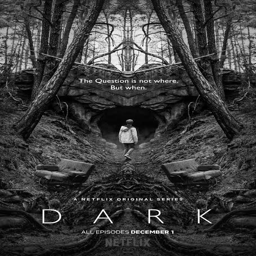

Original vs reconstructed


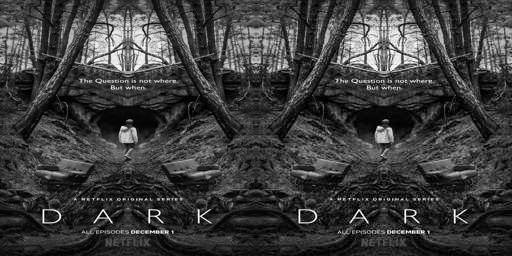

In [10]:
# FT1 — Structured output dashboard
# This cell intentionally shows the intermediate RESULTS as compact sections/tables
# (similar to the reference hard-copy layout), rather than dumping the whole image.

from PIL import Image
from IPython.display import display, HTML
import numpy as np
import re, os, struct, math

# ---------- 1) Export files produced by the C pipeline ----------
gray_img = Image.open("grayscale.pgm").convert("L")
recon_img = Image.open("reconstructed.pgm").convert("L")

# Viewable reconstructed/compressed-image exports.
recon_img.save("reconstructed.png")
recon_img.save("compressed_image.jpg", quality=40, optimize=True)

# Pack the Huffman 0/1 stream into real bytes.
with open("bitstream.txt", "r", encoding="utf-8") as f:
    bitstream = "".join(ch for ch in f.read() if ch in "01")

packed = bytes(
    int(bitstream[i:i+8].ljust(8, "0"), 2)
    for i in range(0, len(bitstream), 8)
)

# Simple self-contained binary container:
# magic | width | height | valid_bit_count | packed Huffman bits
with open("huffman_compressed.hufbin", "wb") as f:
    f.write(b"HUF1")
    f.write(struct.pack("<IIQ", gray_img.width, gray_img.height, len(bitstream)))
    f.write(packed)

# ---------- 2) Recreate the sample 8×8 calculations for clean tables ----------
Q = np.array([
    [16,11,10,16,24,40,51,61],
    [12,12,14,19,26,58,60,55],
    [14,13,16,24,40,57,69,56],
    [14,17,22,29,51,87,80,62],
    [18,22,37,56,68,109,103,77],
    [24,35,55,64,81,104,113,92],
    [49,64,78,87,103,121,120,101],
    [72,92,95,98,112,100,103,99]
], dtype=int)

zz = [
    (0,0),(0,1),(1,0),(2,0),(1,1),(0,2),(0,3),(1,2),
    (2,1),(3,0),(4,0),(3,1),(2,2),(1,3),(0,4),(0,5),
    (1,4),(2,3),(3,2),(4,1),(5,0),(6,0),(5,1),(4,2),
    (3,3),(2,4),(1,5),(0,6),(0,7),(1,6),(2,5),(3,4),
    (4,3),(5,2),(6,1),(7,0),(7,1),(6,2),(5,3),(4,4),
    (3,5),(2,6),(1,7),(2,7),(3,6),(4,5),(5,4),(6,3),
    (7,2),(7,3),(6,4),(5,5),(4,6),(3,7),(4,7),(5,6),
    (6,5),(7,4),(7,5),(6,6),(5,7),(6,7),(7,6),(7,7)
]

gray = np.array(gray_img, dtype=float)
h, w = gray.shape
bx = (w // 2 // 8) * 8
by = (h // 2 // 8) * 8
raw = gray[by:by+8, bx:bx+8]
shifted = raw - 128.0

dct = np.zeros((8,8), dtype=float)
for u in range(8):
    for v in range(8):
        cu = 1/np.sqrt(2) if u == 0 else 1.0
        cv = 1/np.sqrt(2) if v == 0 else 1.0
        s = 0.0
        for x in range(8):
            for y in range(8):
                s += shifted[x,y] * np.cos((2*x+1)*u*np.pi/16) * np.cos((2*y+1)*v*np.pi/16)
        dct[u,v] = 0.25 * cu * cv * s

quant = np.rint(dct / Q).astype(int)
zigzag = np.array([quant[i,j] for i,j in zz], dtype=int)

rle = []
run = 0
for value in zigzag:
    if value == 0:
        run += 1
    else:
        if run:
            rle.append((0, run))
            run = 0
        rle.append((value, 1))
rle.append(("EOB", ""))

# ---------- 3) Parse Huffman table and statistics from the C output ----------
txt = open("outputs.txt", "r", encoding="utf-8").read()

stats = {}
for key, pattern in [
    ("tokens", r"TOTAL TOKENS:\s*(\d+)"),
    ("original_bits", r"ORIGINAL GRAYSCALE PAYLOAD:\s*(\d+) bits"),
    ("compressed_bits", r"HUFFMAN-CODED PAYLOAD:\s*(\d+) bits"),
    ("ratio", r"COMPRESSION RATIO:\s*([0-9.]+):1"),
    ("reduction", r"DATA REDUCTION:\s*([0-9.]+)%"),
    ("mse", r"MSE:\s*([0-9.]+)"),
    ("psnr", r"PSNR:\s*([0-9.]+) dB"),
]:
    m = re.search(pattern, txt)
    stats[key] = float(m.group(1)) if m else None

huff_rows = []
in_huff = False
for line in txt.splitlines():
    if line.strip() == "HUFFMAN TABLE":
        in_huff = True
        continue
    if in_huff:
        if line.startswith("Symbol\tFrequency\tCode"):
            continue
        if not line.strip():
            break
        parts = line.split("\t")
        if len(parts) == 3:
            try:
                huff_rows.append((parts[0], int(parts[1]), parts[2]))
            except ValueError:
                pass
huff_rows = sorted(huff_rows, key=lambda x: x[1], reverse=True)
top10 = huff_rows[:10]

# ---------- 4) Helpers for readable notebook tables ----------
def matrix_html(a, decimals=0, cell_width=58):
    a = np.asarray(a)
    rows = []
    for row in a:
        cells = []
        for x in row:
            if decimals:
                s = f"{float(x):.{decimals}f}"
            else:
                s = str(int(x))
            cells.append(f"<td style='min-width:{cell_width}px'>{s}</td>")
        rows.append("<tr>" + "".join(cells) + "</tr>")
    return "<table class='mx'>" + "".join(rows) + "</table>"

def seq_html(values, per_line=16):
    chunks = []
    for i in range(0, len(values), per_line):
        chunks.append(" ".join(str(x) for x in values[i:i+per_line]))
    return "<div class='seq'>" + "<br>".join(chunks) + "</div>"

def card(n, title, subtitle, body, cls=""):
    return f"""
    <section class='card {cls}'>
      <div class='section-head'><span class='num'>{n}</span><div>
        <div class='title'>{title}</div><div class='sub'>{subtitle}</div>
      </div></div>
      {body}
    </section>
    """

# ---------- 5) Build the hard-copy-style output ----------
css = """
<style>
.ft1 {font-family:Arial,sans-serif; color:#172033; max-width:1200px; margin:auto}
.ft1 .header {padding:16px 18px; border:1px solid #cbd5e1; border-radius:12px; background:#f8fafc; margin-bottom:12px}
.ft1 .header h1 {margin:0 0 5px; font-size:24px}
.ft1 .header p {margin:3px 0; color:#536174}
.ft1 .grid {display:grid; grid-template-columns:repeat(2,minmax(0,1fr)); gap:12px}
.ft1 .card {border:1px solid #cbd5e1; border-radius:12px; padding:14px; background:white; overflow:auto}
.ft1 .wide {grid-column:1/-1}
.ft1 .section-head {display:flex; gap:10px; align-items:center; margin-bottom:10px}
.ft1 .num {font-weight:700; font-size:18px; min-width:28px; height:28px; line-height:28px; text-align:center; border-radius:50%; background:#eef2ff}
.ft1 .title {font-weight:700; font-size:17px}
.ft1 .sub {font-size:12px; color:#64748b}
.ft1 .mx {border-collapse:collapse; margin:6px auto 10px; font-family:monospace; font-size:12px}
.ft1 .mx td {border:1px solid #aeb8c5; padding:5px 4px; text-align:center}
.ft1 .seq {font-family:monospace; font-size:12px; line-height:1.7; padding:9px; background:#f8fafc; border:1px solid #dbe2ea; border-radius:8px; overflow-wrap:anywhere}
.ft1 .two {display:grid; grid-template-columns:1fr 1fr; gap:12px}
.ft1 table.data {width:100%; border-collapse:collapse; font-size:12px}
.ft1 table.data th,.ft1 table.data td {border:1px solid #cbd5e1; padding:6px; text-align:center}
.ft1 table.data th {background:#f1f5f9}
.ft1 .stats {display:grid; grid-template-columns:repeat(4,1fr); gap:8px}
.ft1 .stat {padding:10px; border:1px solid #dbe2ea; border-radius:8px; text-align:center; background:#f8fafc}
.ft1 .stat b {display:block; font-size:18px; margin-top:3px}
.ft1 .thumbs {display:flex; gap:14px; justify-content:center; flex-wrap:wrap}
.ft1 .thumb {text-align:center; font-size:12px; color:#475569}
.ft1 .thumb img {max-width:180px; max-height:210px; border:1px solid #cbd5e1; border-radius:6px}
.ft1 .flow {font-weight:700; text-align:center; padding:8px; background:#f8fafc; border-radius:8px}
@media(max-width:850px){.ft1 .grid,.ft1 .two{grid-template-columns:1fr}.ft1 .stats{grid-template-columns:repeat(2,1fr)}}
</style>
"""

# Small image thumbnails only — no giant raw image output.
from io import BytesIO
import base64
def thumb_data(im, max_size=(180,210)):
    x=im.copy()
    x.thumbnail(max_size)
    buf=BytesIO()
    x.save(buf, format="PNG")
    return "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()

original = Image.open(input_name).convert("RGB")
orig_src = thumb_data(original)
gray_src = thumb_data(gray_img)
recon_src = thumb_data(recon_img)

rle_rows = "".join(
    f"<tr><td>{a}</td><td>{b}</td></tr>" for a,b in rle
)

huff_html = "<table class='data'><tr><th>Symbol</th><th>Frequency</th><th>Probability</th><th>Huffman Code</th></tr>"
total_freq = sum(r[1] for r in huff_rows) or 1
for sym, freq, code in top10:
    huff_html += f"<tr><td>{sym}</td><td>{freq}</td><td>{freq/total_freq:.4f}</td><td><code>{code}</code></td></tr>"
huff_html += "</table>"

sample_codes = "<div class='seq'>" + " &nbsp; ".join(
    f"<b>{s}</b> → {c}" for s,f,c in top10
) + "</div>"

preview = " ".join(bitstream[:160][i:i+8] for i in range(0, min(160,len(bitstream)), 8))
preview += " …"

decoded_preview = open("decoded.txt", "r", encoding="utf-8").read()
m = re.search(r"DECODED TOKEN SEQUENCE PREVIEW\n(.*?)\nTOTAL", decoded_preview, re.S)
decoded_seq = m.group(1).strip() if m else "See decoded.txt"

# Approx inverse-quantized sample and reconstructed sample block
invq = quant * Q
idct = np.zeros((8,8), dtype=float)
for x in range(8):
    for y in range(8):
        s=0.0
        for u in range(8):
            for v in range(8):
                cu = 1/np.sqrt(2) if u == 0 else 1.0
                cv = 1/np.sqrt(2) if v == 0 else 1.0
                s += cu*cv*invq[u,v]*np.cos((2*x+1)*u*np.pi/16)*np.cos((2*y+1)*v*np.pi/16)
        idct[x,y]=0.25*s + 128

html = css + "<div class='ft1'>"
html += f"""
<div class='header'>
<h1>COMPRESSION ANALYSIS & HUFFMAN CODING OF A POSTER IMAGE</h1>
<p>Structured intermediate outputs — sample centre 8×8 block, RLE/Huffman data and reconstruction quality.</p>
<p><b>Input:</b> {original.width}×{original.height} → <b>Processing:</b> {w}×{h} grayscale, 8×8 blocks</p>
</div><div class='grid'>
"""

html += card("1","INPUT IMAGE","Original image", f"""
<div class='thumbs'><div class='thumb'><img src='{orig_src}'><br>Original input</div>
<div class='thumb'><img src='{gray_src}'><br>Grayscale conversion</div></div>
""")

html += card("2","GRAYSCALE CONVERSION","RGB → Y = 0.299R + 0.587G + 0.114B",
f"<div class='flow'>Each pixel becomes one 0–255 intensity value.</div>")

html += card("3","8×8 BLOCK FORMATION","Centre sample block from grayscale image",
matrix_html(raw))

html += card("4","DCT COEFFICIENTS","Level shift first: pixel − 128",
matrix_html(dct,2) + "<p style='text-align:center;color:#64748b'>Low-frequency energy is concentrated near the top-left.</p>")

html += card("5","QUANTIZATION","Standard JPEG quantization table and quantized DCT",
"<div class='two'><div><b>Quantization Table Q</b>"+matrix_html(Q)+"</div><div><b>Quantized DCT</b>"+matrix_html(quant)+"</div></div>")

html += card("6","ZIGZAG SCAN","64 coefficients — low frequencies first",
seq_html(zigzag.tolist(), 16))

html += card("7","RUN-LENGTH ENCODING (RLE)","Zeros are represented by (0, run length); EOB ends the block",
f"""<div class='two'><div><table class='data'><tr><th>Value / token</th><th>Run</th></tr>{rle_rows}</table></div>
<div><b>RLE sequence</b>{seq_html([f"{a}" if b==1 else f"(0,{b})" if b else "EOB" for a,b in rle], 8)}</div></div>""")

html += card("8","HUFFMAN CODING","Frequency-based variable-length coding",
huff_html + "<p style='font-size:12px;color:#64748b'>Top 10 symbols shown for readability; the complete table is saved in outputs.txt.</p>" + sample_codes)

html += card("9","ENCODED BITSTREAM","RLE tokens replaced by Huffman codes",
f"""<div class='seq'>{preview}</div>
<p style='text-align:center'>Only the bitstream is stored in the compressed payload; the binary export is <b>huffman_compressed.hufbin</b>.</p>""")

html += card("10","DECODING & RECONSTRUCTION","Huffman decoding → RLE decoding → inverse quantization → IDCT",
f"""<div class='flow'>Huffman Decoding → RLE Decoding → Inverse Quantization (× Q) → IDCT (+128) → Reconstructed pixels</div>
<div class='two' style='margin-top:10px'><div><b>Decoded token preview</b>{seq_html(decoded_seq.split(), 10)}</div>
<div><b>Inverse-quantized sample block</b>{matrix_html(invq,0)}</div></div>
<h4>Sample IDCT / reconstructed 8×8 block</h4>{matrix_html(idct,0)}</div>""")

html += card("11","OUTPUT IMAGE","After decompression / reconstruction",
f"""<div class='thumbs'>
<div class='thumb'><img src='{gray_src}'><br>Original grayscale</div>
<div class='thumb'><img src='{recon_src}'><br>Reconstructed image</div>
</div>""")

html += card("12","COMPRESSION STATISTICS","Measured from the Huffman-coded bitstream",
f"""<div class='stats'>
<div class='stat'>Original grayscale payload<b>{int(stats['original_bits']):,} bits</b></div>
<div class='stat'>Huffman payload<b>{int(stats['compressed_bits']):,} bits</b></div>
<div class='stat'>Compression ratio<b>{stats['ratio']:.4f} : 1</b></div>
<div class='stat'>Data reduction<b>{stats['reduction']:.2f}%</b></div>
<div class='stat'>MSE<b>{stats['mse']:.6f}</b></div>
<div class='stat'>PSNR<b>{stats['psnr']:.4f} dB</b></div>
<div class='stat'>Huffman stream bytes<b>{len(packed):,}</b></div>
<div class='stat'>Valid Huffman bits<b>{len(bitstream):,}</b></div>
</div>
<p><b>Compression-ratio formula:</b> Original bits ÷ Huffman-coded bits = {int(stats['original_bits']):,} ÷ {int(stats['compressed_bits']):,} = <b>{stats['ratio']:.4f}:1</b>.</p>
""")

html += """</div></div>"""
display(HTML(html))

print("Exports created:")
for name in [
    "huffman_compressed.hufbin",
    "compressed_image.jpg",
    "reconstructed.png",
    "grayscale.pgm",
    "reconstructed.pgm",
    "outputs.txt",
    "bitstream.txt",
    "decoded.txt"
]:
    if os.path.exists(name):
        print("✓", name)


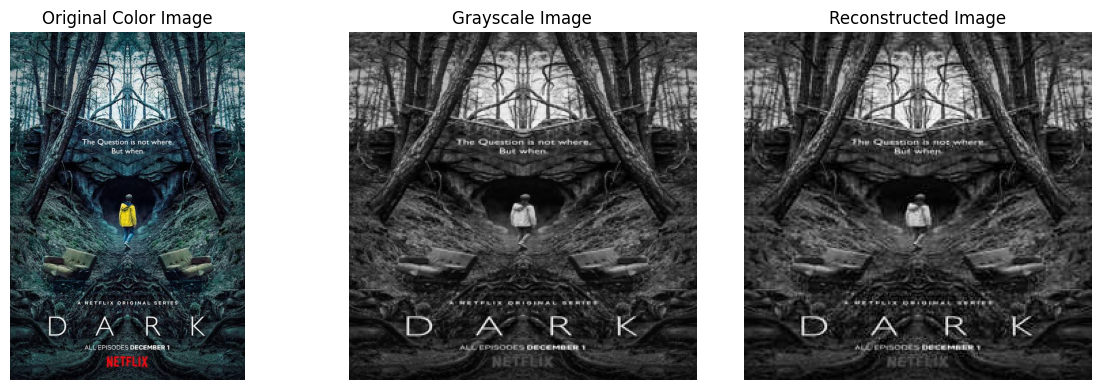

In [11]:
# Assignment files
# The notebook output above is the formatted hard-copy-style result.
# Use these commands in Colab when you want to download the outputs.

from google.colab import files
import os

print("Available files:")
for name in [
    "image_compression.c",
    "huffman_compressed.hufbin",
    "compressed_image.jpg",
    "reconstructed.png",
    "grayscale.pgm",
    "reconstructed.pgm",
    "outputs.txt",
    "bitstream.txt",
    "decoded.txt"
]:
    if os.path.exists(name):
        print("✓", name)

# Example:
# files.download("huffman_compressed.hufbin")
# files.download("compressed_image.jpg")
# files.download("outputs.txt")


In [12]:
# Quick text summary (no large image dump)
print(open("outputs.txt", encoding="utf-8").read())


IMAGE COMPRESSION OUTPUTS

Original image dimensions: 256 x 256
Padded dimensions: 256 x 256

8x8 SAMPLE BLOCK (center block)
      77      68     118     185     207     216     211     143
      85     130     143     150     173     190     194     196
     129     176     131      88     155     178     198     211
     156     181     146      88     145     171     198     204
     185     181     149     114     168     198     191     197
     206     179     162     110     151     187     193     201
     193     177     153     119     137     187     184     201
     201     170     145     149     110     149     179     197

LEVEL SHIFTED BLOCK
    -51.00    -60.00    -10.00     57.00     79.00     88.00     83.00     15.00
    -43.00      2.00     15.00     22.00     45.00     62.00     66.00     68.00
      1.00     48.00      3.00    -40.00     27.00     50.00     70.00     83.00
     28.00     53.00     18.00    -40.00     17.00     43.00     70.00     76.00
     57.0

In [13]:
print("For the hard-copy submission, use the formatted output from the previous cell.")
print("The main visual output is divided into numbered sections 1–12, with compact matrices/tables.")
print("The compressed Huffman payload is exported as: huffman_compressed.hufbin")
print("The reconstructed image is exported as: reconstructed.png")
print("A JPEG view is exported as: compressed_image.jpg")


Files to use for your assignment:
1. image_compression.c — print as your code
2. grayscale.pgm — grayscale output
3. reconstructed.pgm — reconstructed output
4. outputs.txt — DCT, quantization, zigzag, RLE, Huffman and compression results
5. bitstream.txt — complete Huffman-coded payload
6. decoded.txt — decoded token output
